# Day 2 — Data Preparation & Customer/Restaurant Segmentation

## Objective
Use unsupervised learning to identify patterns among customers and restaurants in the synthetic Uber Eats dataset generated on Day 1.

## Workflow
1. Load and inspect the raw datasets.
2. Engineer customer-level and restaurant-level features.
3. Treat missing values and standardize features.
4. Compare K-Means cluster counts with the elbow method and silhouette score.
5. Use DBSCAN to examine density-based groups and potential noise points.
6. Use PCA to visualize clusters.
7. Interpret cluster profiles and save outputs for business review.

**Important:** IDs and descriptive names are retained in exported tables for traceability, but IDs are not included in model features.

## 1. Imports and project setup

This notebook uses the same reusable functions as `src/segmentation.py`. Keeping the implementation in a Python module avoids duplicating the full pipeline and makes it easier to rerun the same steps from a script.

Run this notebook from the project root, or open it in the existing project in VS Code.

In [1]:
from pathlib import Path
import sys

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "raw").exists():
    PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src import segmentation as seg

print("Project folder:", PROJECT_DIR)
print("Raw data folder:", PROJECT_DIR / "data" / "raw")

DATASETS LOADED SUCCESSFULLY
Customers: (2000, 5)
Restaurants: (150, 6)
Orders: (10000, 7)
Deliveries: (9012, 8)
Reviews: (6038, 6)

CUSTOMER FEATURES CREATED
  customer_id  total_orders  weekend_orders  late_night_orders  \
0    CUST0001           6.0             1.0                0.0   
1    CUST0002           6.0             3.0                1.0   
2    CUST0003           7.0             2.0                0.0   
3    CUST0004           2.0             1.0                0.0   
4    CUST0005           6.0             2.0                0.0   

   ordering_frequency  total_spending  average_order_value  \
0            0.801053         4429.10           885.820000   
1            0.761000         2038.72           407.744000   
2            0.774836         5782.94           963.823333   
3            0.951250         1414.17           707.085000   
4            0.710661         5262.90           877.150000   

   average_rating_given  
0              4.000000  
1              2.33

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Load and inspect the data

Before feature engineering, inspect row counts and column names. This helps confirm that the generated files are present and that the expected schema is available.

In [3]:
RAW_DIR = PROJECT_DIR / "data" / "raw"

customers = pd.read_csv(RAW_DIR / "customers.csv")
restaurants = pd.read_csv(RAW_DIR / "restaurants.csv")
orders = pd.read_csv(RAW_DIR / "orders.csv")
deliveries = pd.read_csv(RAW_DIR / "deliveries.csv")
reviews = pd.read_csv(RAW_DIR / "reviews.csv")

for name, df in {
    "customers": customers,
    "restaurants": restaurants,
    "orders": orders,
    "deliveries": deliveries,
    "reviews": reviews,
}.items():
    print(f"{name}: {df.shape}")
    display(df.head(3))

customers: (2000, 5)


,customer_id,age,city,signup_date,membership_type
0,CUST0001,22,Pune,2024-02-18,Gold
1,CUST0002,55,Bengaluru,2022-09-12,Silver
2,CUST0003,49,Delhi,2024-11-26,Regular


restaurants: (150, 6)


,restaurant_id,restaurant_name,city,cuisine_type,restaurant_rating,avg_preparation_time
0,REST001,Restaurant 001,Delhi,Mexican,4.25,32
1,REST002,Restaurant 002,Mumbai,Chinese,2.99,27
2,REST003,Restaurant 003,Hyderabad,Fast Food,3.84,12


orders: (10000, 7)


,order_id,customer_id,restaurant_id,order_timestamp,order_amount,num_items,order_status
0,ORD07789,CUST0388,REST014,2025-01-01 02:50:28,285.61,3,Completed
1,ORD06434,CUST1183,REST045,2025-01-01 03:23:37,532.80,4,Completed
2,ORD08127,CUST0110,REST145,2025-01-01 03:56:16,858.49,6,Completed


deliveries: (9012, 8)


,delivery_id,order_id,driver_id,delivery_distance_km,preparation_time_minutes,delivery_time_minutes,traffic_condition,weather_condition
0,DEL00001,ORD07789,DRV0109,2.30,38,42,Medium,Cloudy
1,DEL00002,ORD06434,DRV0234,4.03,38,56,Medium,Rainy
2,DEL00003,ORD08127,DRV0082,3.01,34,55,High,Cloudy


reviews: (6038, 6)


,review_id,order_id,customer_id,restaurant_id,review_text,review_rating
0,REV00001,ORD07160,CUST0636,REST129,The order took too long to arrive.,2
1,REV00002,ORD00831,CUST0871,REST129,Great taste and excellent service.,5
2,REV00003,ORD01714,CUST0812,REST138,The food was delicious and arrived on time.,4


## 3. Customer feature engineering

Customer features summarize order frequency, completed-order spending, ratings given, weekend ordering, and late-night ordering. The customer ID is used only to join the features back to the customer table; it is not a model input.

In [15]:
# Prepare order timestamps and numeric order amounts.
orders["order_timestamp"] = pd.to_datetime(orders["order_timestamp"], errors="coerce")
orders["order_amount"] = pd.to_numeric(orders["order_amount"], errors="coerce")
orders["order_status"] = orders["order_status"].astype("string").str.strip().str.lower()

completed_orders = orders[orders["order_status"] == "completed"].copy()
orders["order_hour"] = orders["order_timestamp"].dt.hour
orders["is_weekend"] = (orders["order_timestamp"].dt.day_of_week >= 5).astype(int)
orders["is_late_night"] = ((orders["order_hour"] >= 22) | (orders["order_hour"] < 5)).astype(int)

customer_order_features = orders.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    weekend_orders=("is_weekend", "sum"),
    late_night_orders=("is_late_night", "sum"),
    first_order_date=("order_timestamp", "min"),
    last_order_date=("order_timestamp", "max"),
).reset_index()

active_days = (customer_order_features["last_order_date"] - customer_order_features["first_order_date"]).dt.days
active_months = (active_days / 30.44).clip(lower=1)
customer_order_features["ordering_frequency"] = customer_order_features["total_orders"] / active_months

customer_spending = completed_orders.groupby("customer_id").agg(
    total_spending=("order_amount", "sum"),
    average_order_value=("order_amount", "mean"),
).reset_index()

customer_ratings = reviews.groupby("customer_id").agg(
    average_rating_given=("review_rating", "mean")
).reset_index()

customer_features = customers[["customer_id"]].copy()
customer_features = customer_features.merge(
    customer_order_features.drop(columns=["first_order_date", "last_order_date"]),
    on="customer_id", how="left"
)
customer_features = customer_features.merge(customer_spending, on="customer_id", how="left")
customer_features = customer_features.merge(customer_ratings, on="customer_id", how="left")

customer_feature_columns = [
    "total_orders", "average_order_value", "total_spending",
    "ordering_frequency", "average_rating_given",
    "weekend_orders", "late_night_orders"
]
customer_features[customer_feature_columns] = customer_features[customer_feature_columns].replace([np.inf, -np.inf], np.nan)

display(customer_features.head())
print("Customer feature shape:", customer_features.shape)

,customer_id,total_orders,weekend_orders,late_night_orders,ordering_frequency,total_spending,average_order_value,average_rating_given
0,CUST0001,6.0,1.0,0.0,0.801053,4429.10,885.820000,4.000000
1,CUST0002,6.0,3.0,1.0,0.761000,2038.72,407.744000,2.333333
2,CUST0003,7.0,2.0,0.0,0.774836,5782.94,963.823333,2.500000
3,CUST0004,2.0,1.0,0.0,0.951250,1414.17,707.085000,5.000000
4,CUST0005,6.0,2.0,0.0,0.710661,5262.90,877.150000,4.000000


Customer feature shape: (2000, 8)


### Observation and transition

Review the feature table for missing values and check whether customers with no orders are retained. Missing numerical features will be imputed during preprocessing. Next, create restaurant-level operational and performance features.

In [5]:
print("Missing customer feature values:")
display(customer_features[customer_feature_columns].isna().sum().to_frame("missing_count"))

Missing customer feature values:


,missing_count
total_orders,16
average_order_value,17
total_spending,17
ordering_frequency,16
average_rating_given,102
weekend_orders,16
late_night_orders,16


## 4. Restaurant feature engineering

Restaurant features summarize order volume, revenue from completed orders, cancellation rate, ratings, preparation time, and delivery time. Restaurant names and IDs are retained for interpretation but excluded from clustering.

In [6]:
restaurant_order_features = orders.groupby("restaurant_id").agg(
    total_orders=("order_id", "nunique")
).reset_index()

restaurant_revenue = completed_orders.groupby("restaurant_id").agg(
    revenue=("order_amount", "sum")
).reset_index()

cancelled_orders = orders.copy()
cancelled_orders["is_cancelled"] = (cancelled_orders["order_status"] == "cancelled").astype(int)
restaurant_cancellations = cancelled_orders.groupby("restaurant_id").agg(
    cancellation_rate=("is_cancelled", "mean")
).reset_index()

delivery_details = deliveries.merge(
    orders[["order_id", "restaurant_id"]], on="order_id", how="inner"
)
for col in ["preparation_time_minutes", "delivery_time_minutes"]:
    delivery_details[col] = pd.to_numeric(delivery_details[col], errors="coerce")

restaurant_delivery_features = delivery_details.groupby("restaurant_id").agg(
    average_preparation_time=("preparation_time_minutes", "mean"),
    average_delivery_time=("delivery_time_minutes", "mean")
).reset_index()

restaurant_ratings = reviews.groupby("restaurant_id").agg(
    average_rating=("review_rating", "mean")
).reset_index()

restaurant_features = restaurants[
    ["restaurant_id", "restaurant_name", "restaurant_rating", "avg_preparation_time"]
].copy()

for extra in [
    restaurant_order_features, restaurant_revenue, restaurant_cancellations,
    restaurant_delivery_features, restaurant_ratings
]:
    restaurant_features = restaurant_features.merge(
        extra, on="restaurant_id", how="left"
    )

restaurant_features["average_rating"] = restaurant_features["average_rating"].fillna(
    restaurant_features["restaurant_rating"]
)
restaurant_features["average_preparation_time"] = restaurant_features["average_preparation_time"].fillna(
    restaurant_features["avg_preparation_time"]
)

restaurant_feature_columns = [
    "total_orders", "revenue", "average_rating",
    "average_preparation_time", "cancellation_rate", "average_delivery_time"
]
restaurant_features[restaurant_feature_columns] = restaurant_features[
    restaurant_feature_columns
].replace([np.inf, -np.inf], np.nan)

restaurant_features = restaurant_features.drop(
    columns=["restaurant_rating", "avg_preparation_time"]
)

display(restaurant_features.head())
print("Restaurant feature shape:", restaurant_features.shape)

,restaurant_id,restaurant_name,total_orders,revenue,cancellation_rate,average_preparation_time,average_delivery_time,average_rating
0,REST001,Restaurant 001,72,50530.41,0.055556,32.515625,51.875000,3.822222
1,REST002,Restaurant 002,57,37569.50,0.087719,27.180000,45.320000,3.387097
2,REST003,Restaurant 003,67,32583.40,0.134328,12.648148,38.166667,3.777778
3,REST004,Restaurant 004,59,42190.77,0.016949,29.625000,50.607143,3.421053
4,REST005,Restaurant 005,84,50344.44,0.059524,33.229730,50.013514,3.489362


Restaurant feature shape: (150, 8)


### Observation and transition

Inspect missing values in restaurant features. For example, a restaurant with no completed orders may have missing revenue. The preprocessing step will impute missing numerical values before standardization. Next, prepare model-ready feature matrices.

In [7]:
print("Missing restaurant feature values:")
display(restaurant_features[restaurant_feature_columns].isna().sum().to_frame("missing_count"))

Missing restaurant feature values:


,missing_count
total_orders,0
revenue,0
average_rating,0
average_preparation_time,0
cancellation_rate,0
average_delivery_time,0


## 5. Missing-value treatment and standardization

K-Means and DBSCAN use distance calculations. If features are on very different scales, large-valued variables such as revenue can dominate smaller-valued variables such as ratings. Median imputation handles missing numerical values, and `StandardScaler` puts the selected features on a comparable scale.

Identifiers and names are deliberately excluded from the feature matrices.

In [8]:
customer_X, customer_scaled, customer_columns = seg.prepare_features(
    customer_features, customer_feature_columns, "customer"
)
restaurant_X, restaurant_scaled, restaurant_columns = seg.prepare_features(
    restaurant_features, restaurant_feature_columns, "restaurant"
)

print("Customer model matrix:", customer_scaled.shape)
print("Customer features used:", customer_columns)
print("Restaurant model matrix:", restaurant_scaled.shape)
print("Restaurant features used:", restaurant_columns)

Customer model matrix: (2000, 7)
Customer features used: ['total_orders', 'average_order_value', 'total_spending', 'ordering_frequency', 'average_rating_given', 'weekend_orders', 'late_night_orders']
Restaurant model matrix: (150, 6)
Restaurant features used: ['total_orders', 'revenue', 'average_rating', 'average_preparation_time', 'cancellation_rate', 'average_delivery_time']


## 6. K-Means: Elbow method and silhouette score

The elbow method shows how within-cluster inertia decreases as K increases. The silhouette score evaluates how well separated the resulting clusters are. These metrics should be considered together, and the final choice should also make business sense.

In [9]:
customer_kmeans, customer_kmeans_labels, customer_scores = seg.run_kmeans(
    customer_scaled, "customer", customer_columns
)
restaurant_kmeans, restaurant_kmeans_labels, restaurant_scores = seg.run_kmeans(
    restaurant_scaled, "restaurant", restaurant_columns
)

display(customer_scores)
display(restaurant_scores)


CUSTOMER K-MEANS
Selected K: 2
Silhouette score: 0.2205

RESTAURANT K-MEANS
Selected K: 2
Silhouette score: 0.2469


,k,inertia,silhouette_score
0,2,10711.694066,0.220482
1,3,9508.072163,0.164216
2,4,8547.205958,0.175357
3,5,7843.715232,0.169286
4,6,7205.590021,0.157102
5,7,6716.406232,0.158833
6,8,6399.003247,0.156470


,k,inertia,silhouette_score
0,2,649.362752,0.246934
1,3,548.388811,0.204534
2,4,485.313443,0.185174
3,5,431.345779,0.193289
4,6,393.538039,0.193403
5,7,356.929926,0.203353
6,8,336.144568,0.187379


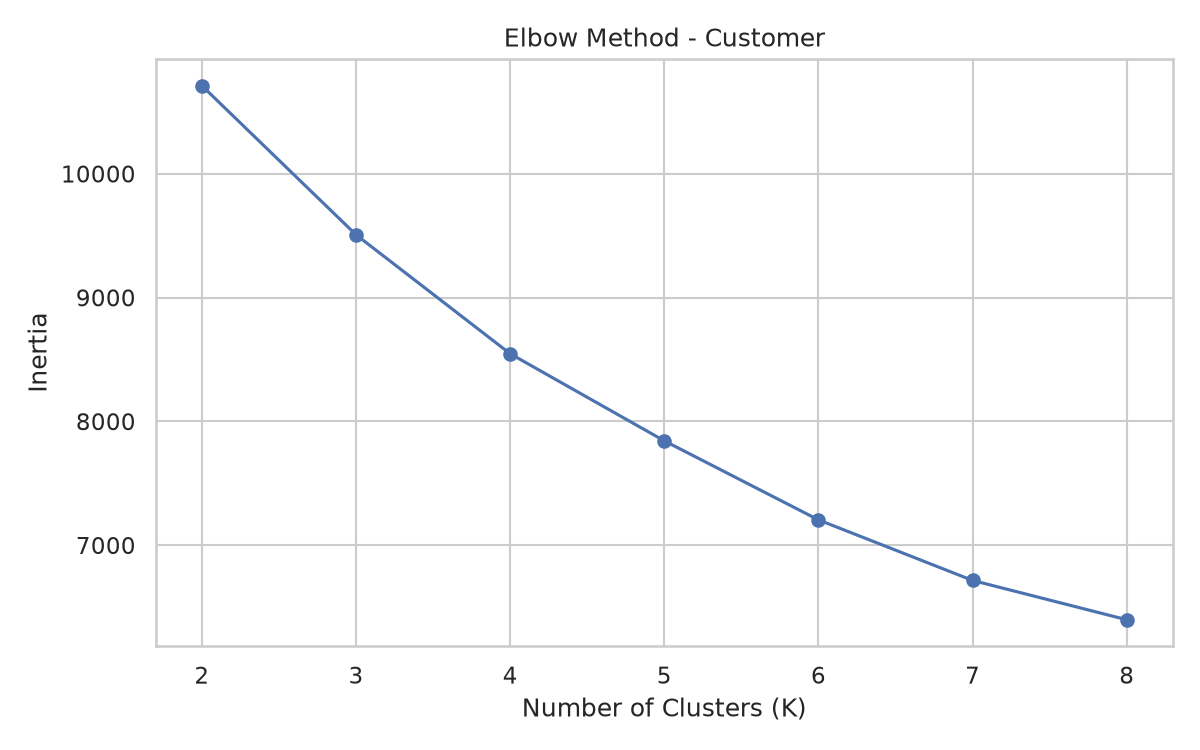

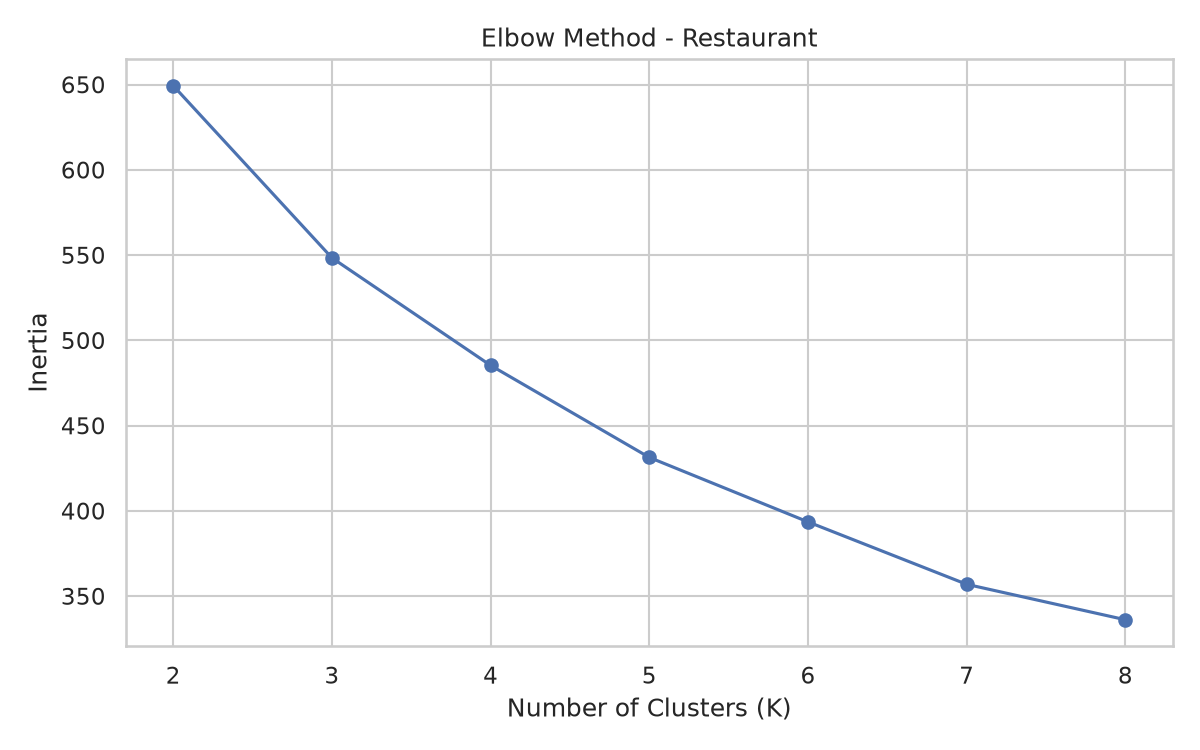

In [10]:
from IPython.display import Image, display

display(Image(filename=str(PROJECT_DIR / "reports" / "figures" / "customer_elbow.png")))
display(Image(filename=str(PROJECT_DIR / "reports" / "figures" / "restaurant_elbow.png")))

### Observation and transition

Compare where the inertia curve begins to flatten and compare silhouette scores across K values. The pipeline selects the tested K with the highest silhouette score; this is a starting point, not a substitute for inspecting cluster profiles. Next, use DBSCAN to investigate density-based groups and potential outliers.

In [11]:
display(customer_scores.sort_values("silhouette_score", ascending=False))
display(restaurant_scores.sort_values("silhouette_score", ascending=False))

,k,inertia,silhouette_score
0,2,10711.694066,0.220482
2,4,8547.205958,0.175357
3,5,7843.715232,0.169286
1,3,9508.072163,0.164216
5,7,6716.406232,0.158833
4,6,7205.590021,0.157102
6,8,6399.003247,0.156470


,k,inertia,silhouette_score
0,2,649.362752,0.246934
1,3,548.388811,0.204534
5,7,356.929926,0.203353
4,6,393.538039,0.193403
3,5,431.345779,0.193289
6,8,336.144568,0.187379
2,4,485.313443,0.185174


## 7. DBSCAN: Dense groups and noise

DBSCAN groups points based on density rather than requiring a predefined number of clusters. Points labelled `-1` are noise points that were not assigned to a cluster. The selected epsilon and the noise percentage should be inspected carefully because DBSCAN can produce one cluster or mostly noise if its parameters do not fit the data.

In [12]:
customer_dbscan, customer_dbscan_labels, customer_dbscan_scores = seg.run_dbscan(
    customer_scaled, "customer"
)
restaurant_dbscan, restaurant_dbscan_labels, restaurant_dbscan_scores = seg.run_dbscan(
    restaurant_scaled, "restaurant"
)

display(customer_dbscan_scores)
display(restaurant_dbscan_scores)


CUSTOMER DBSCAN
Selected epsilon: 1.0
Silhouette score: 0.3362
Noise points: 1095
Noise percentage: 54.75%

RESTAURANT DBSCAN
Selected epsilon: 1.5
Silhouette score: 0.2244
Noise points: 56
Noise percentage: 37.33%


,eps,min_samples,clusters_excluding_noise,noise_points,noise_percentage,silhouette_score
0,0.8,14,5,1816,90.80,0.210954
1,1.0,14,2,1095,54.75,0.336177
2,1.2,14,1,471,23.55,NaN
3,1.5,14,2,135,6.75,0.322646
4,1.8,14,1,46,2.30,NaN
5,2.0,14,1,27,1.35,NaN
6,2.5,14,1,10,0.50,NaN
7,3.0,14,1,4,0.20,NaN


,eps,min_samples,clusters_excluding_noise,noise_points,noise_percentage,silhouette_score
0,0.8,12,0,150,100.000000,NaN
1,1.0,12,0,150,100.000000,NaN
2,1.2,12,0,150,100.000000,NaN
3,1.5,12,3,56,37.333333,0.224416
4,1.8,12,1,11,7.333333,NaN
5,2.0,12,1,3,2.000000,NaN
6,2.5,12,1,0,0.000000,NaN
7,3.0,12,1,0,0.000000,NaN


## 8. PCA visualization

PCA projects the standardized feature matrices into two dimensions so clusters can be visualized. The plots are useful for exploration, but a two-dimensional projection cannot preserve every relationship from the original feature space.


CUSTOMER CLUSTER PROFILES
                total_orders  average_order_value  total_spending  ordering_frequency  average_rating_given  weekend_orders  late_night_orders          cluster_name
kmeans_cluster                                                                                                                                                      
0                   7.051451           713.902144     4502.518694            0.839154              3.790029        2.348285           1.895778        Regular Diners
1                   3.796900           659.527924     2205.293257            0.708449              3.666858        0.921697           0.778956  Low-Rating Reviewers

Saved customer segmentation results.

RESTAURANT CLUSTER PROFILES
                total_orders       revenue  average_rating  average_preparation_time  cancellation_rate  average_delivery_time                  cluster_name
kmeans_cluster                                                                           

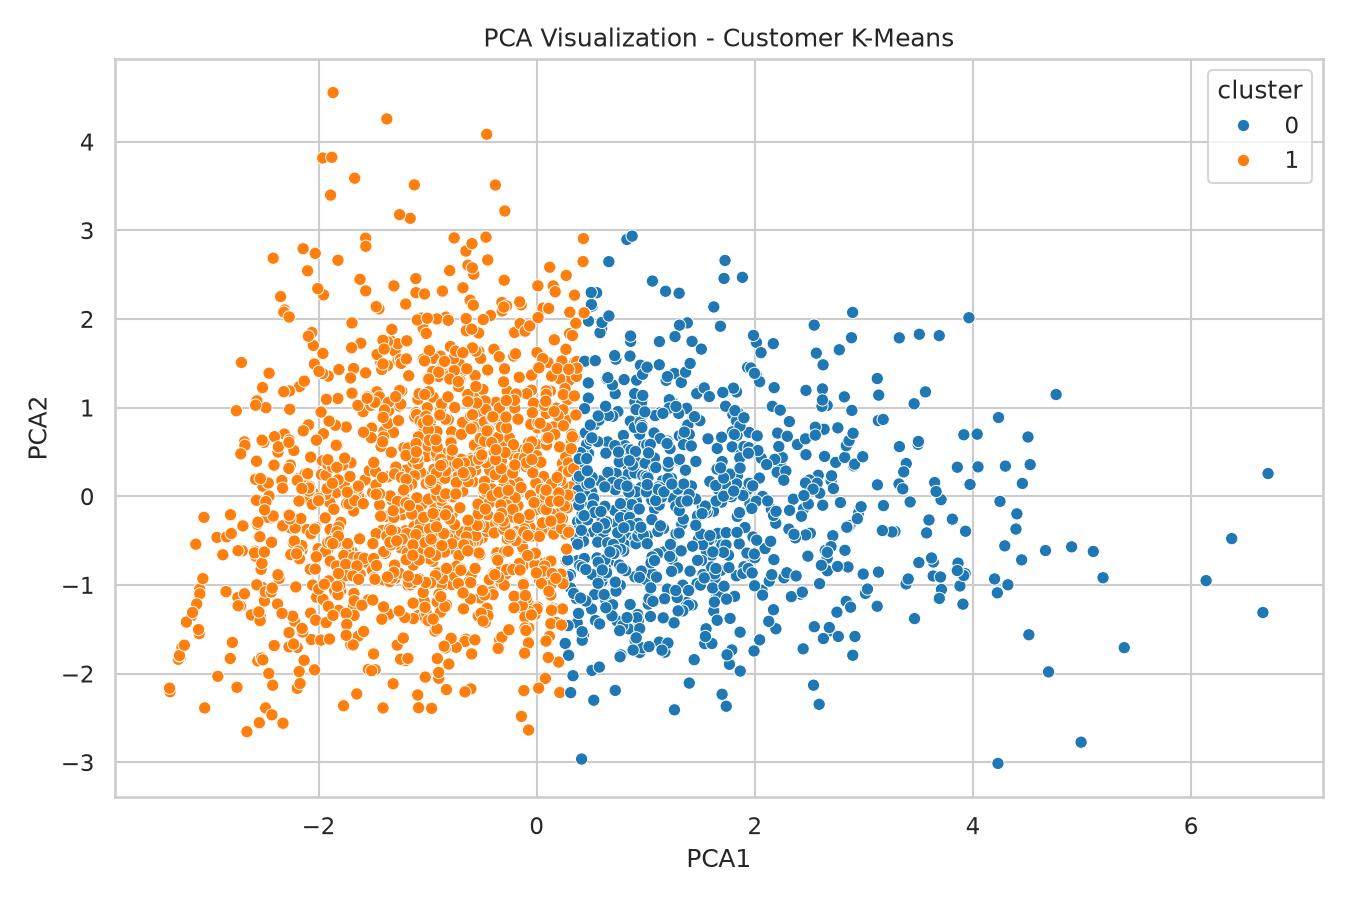

customer_pca_dbscan.png


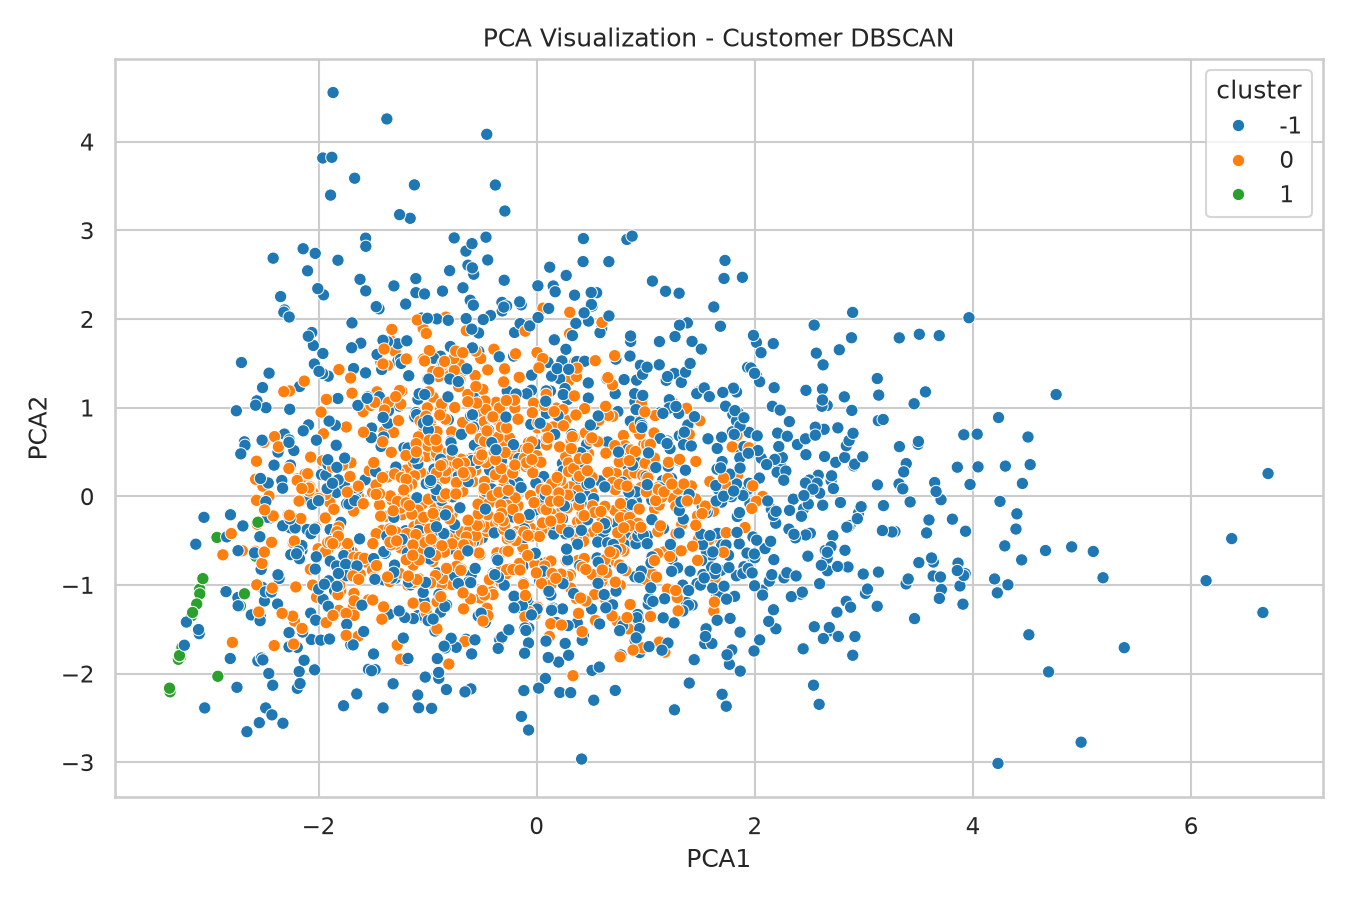

restaurant_pca_kmeans.png


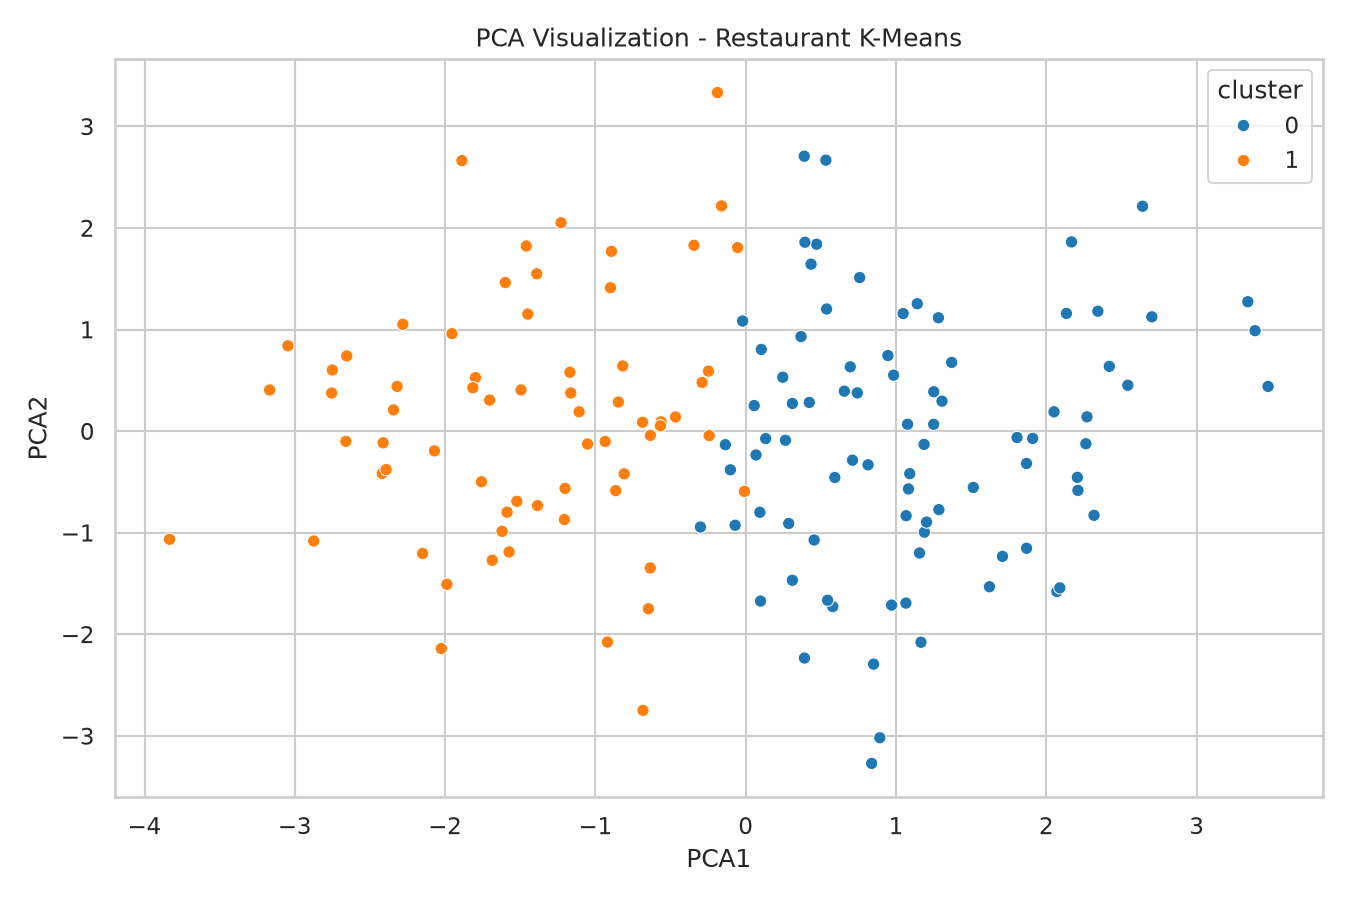

restaurant_pca_dbscan.png


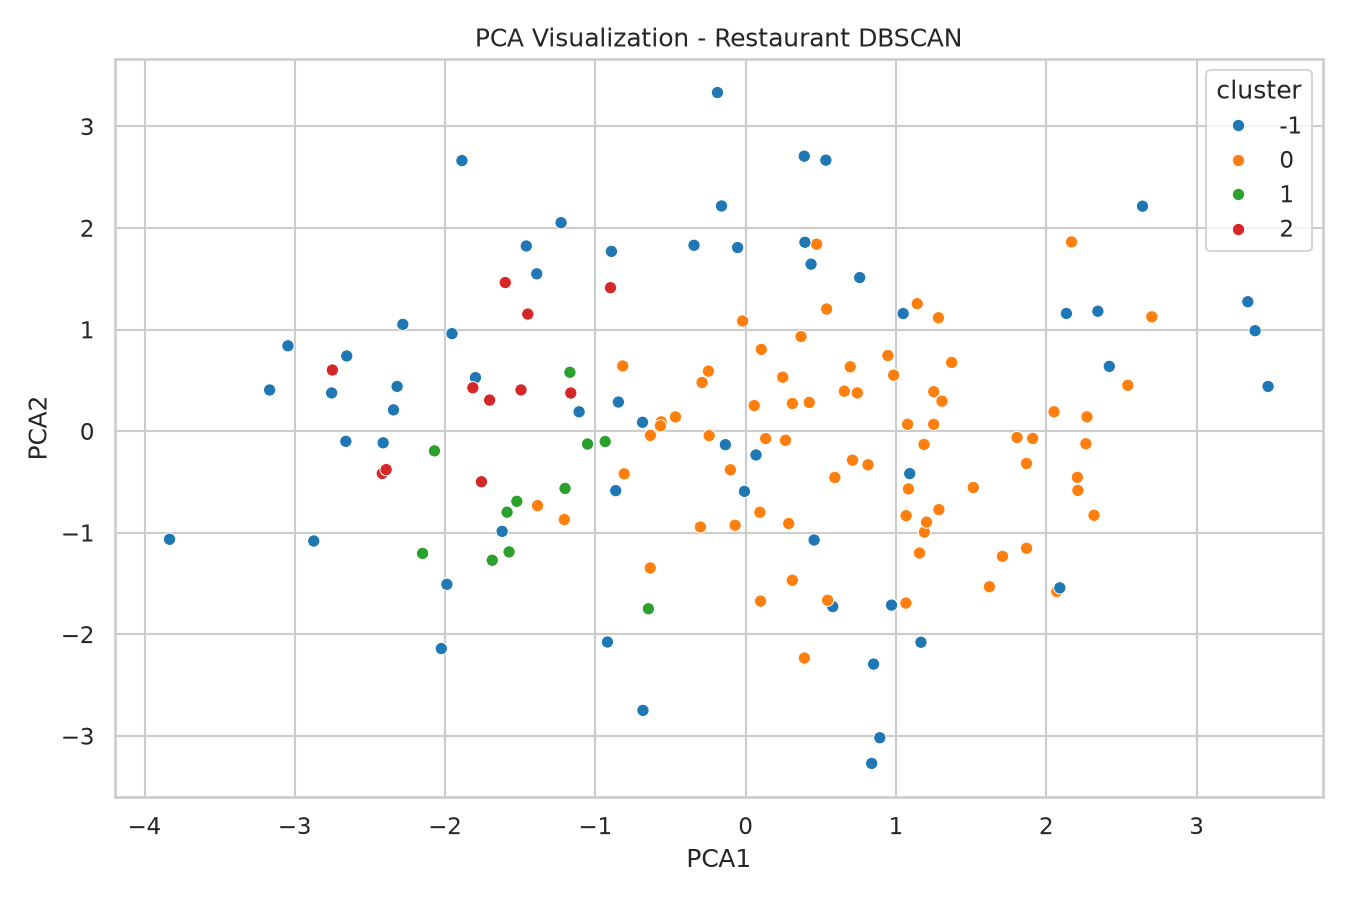

In [13]:
seg.save_results(
    customer_features, customer_X, customer_scaled, customer_columns,
    customer_kmeans_labels, customer_dbscan_labels, "customer"
)
seg.save_results(
    restaurant_features, restaurant_X, restaurant_scaled, restaurant_columns,
    restaurant_kmeans_labels, restaurant_dbscan_labels, "restaurant"
)

for filename in [
    "customer_pca_kmeans.png", "customer_pca_dbscan.png",
    "restaurant_pca_kmeans.png", "restaurant_pca_dbscan.png"
]:
    print(filename)
    display(Image(filename=str(PROJECT_DIR / "reports" / "figures" / filename)))

## 9. Cluster profiles and business interpretation

Cluster profiles show average feature values within each K-Means cluster. Use these tables to explain what differentiates the groups. Automatically generated names are preliminary: check the actual values before presenting names such as “Frequent Diners” or “High-Revenue Restaurants” as conclusions.

In [14]:
customer_profiles = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "customer_cluster_profiles.csv"
)
restaurant_profiles = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "restaurant_cluster_profiles.csv"
)

display(customer_profiles)
display(restaurant_profiles)

print("Customer cluster sizes:")
display(
    pd.read_csv(PROJECT_DIR / "data" / "processed" / "customer_segmented.csv")
      ["cluster_name"].value_counts().to_frame("customer_count")
)

print("Restaurant cluster sizes:")
display(
    pd.read_csv(PROJECT_DIR / "data" / "processed" / "restaurant_segmented.csv")
      ["cluster_name"].value_counts().to_frame("restaurant_count")
)

,kmeans_cluster,total_orders,average_order_value,total_spending,ordering_frequency,average_rating_given,weekend_orders,late_night_orders,cluster_name
0,0,7.051451,713.902144,4502.518694,0.839154,3.790029,2.348285,1.895778,Regular Diners
1,1,3.796900,659.527924,2205.293257,0.708449,3.666858,0.921697,0.778956,Low-Rating Reviewers


,kmeans_cluster,total_orders,revenue,average_rating,average_preparation_time,cancellation_rate,average_delivery_time,cluster_name
0,0,71.023810,44035.958810,3.778753,31.000378,0.064003,49.531579,High-Revenue Restaurants
1,1,61.121212,36596.558636,3.664465,18.700989,0.072257,43.335549,Fast-Preparation Restaurants


Customer cluster sizes:


,customer_count
cluster_name,
Low-Rating Reviewers,1242
Regular Diners,758


Restaurant cluster sizes:


,restaurant_count
cluster_name,
High-Revenue Restaurants,84
Fast-Preparation Restaurants,66


## 10. Business insights and conclusion

Complete this section after reviewing the actual output tables and plots. Do not invent findings before the models have run.

Use the prompts below to write evidence-based observations:
- Which customer cluster has the highest spending or order frequency?
- Which group orders most often on weekends or late at night?
- Which restaurants have high revenue, high ratings, or longer preparation/delivery times?
- Do cancellation rates differ across restaurant clusters?
- Does DBSCAN identify noise points, and what proportion of observations are labelled as noise?
- Which K-Means configuration balances silhouette score, elbow shape, and interpretable cluster profiles?

### Potential business actions
- Tailor loyalty offers to frequent customers.
- Test targeted promotions for occasional customers.
- Consider late-night offers only where operationally feasible.
- Review restaurant operations where long preparation/delivery times coincide with high order volume.
- Investigate high cancellation rates before making partner-level decisions.

These are potential actions to evaluate, not conclusions guaranteed by the synthetic data.

## Deliverables checklist

- [ ] `customer_features.csv`
- [ ] `restaurant_features.csv`
- [ ] `customer_segmented.csv`
- [ ] `restaurant_segmented.csv`
- [ ] Customer and restaurant cluster profiles
- [ ] Elbow plots and silhouette-score tables
- [ ] DBSCAN evaluation tables and noise counts
- [ ] PCA visualizations for K-Means and DBSCAN
- [ ] Saved model and preprocessing files in `models/day2/`
- [ ] Business insights written from the actual results